In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, ElasticNet, ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import root_mean_squared_log_error, r2_score

In [2]:
df_train = pd.read_csv('train.csv')
df_train.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
0,1,4,0,1,2,0.26,0.2576,0.70,0.1642,34,2012,2,4,11
1,2,4,0,1,1,0.58,0.5455,0.64,0.0000,341,2012,11,3,10
2,3,4,0,0,3,0.22,0.1970,0.93,0.3284,67,2011,17,6,10
3,4,1,0,1,2,0.36,0.3636,0.66,0.1045,40,2011,1,3,12
4,5,1,0,0,2,0.04,0.0606,0.41,0.1642,96,2011,10,6,1


In [3]:
df_train.sample(10)

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
5364,5365,4,0,0,1,0.50,0.4848,0.45,0.1940,696,2012,17,6,11
6295,6296,2,0,0,1,0.68,0.6364,0.83,0.0896,63,2011,3,6,6
1705,1706,3,0,0,1,0.70,0.6667,0.74,0.2239,416,2011,18,6,8
2846,2847,2,0,1,1,0.62,0.5909,0.78,0.2537,258,2012,10,2,5
8767,8768,2,0,0,1,0.58,0.5455,0.83,0.2239,328,2011,10,0,5
1702,1703,3,0,1,2,0.68,0.6364,0.79,0.3284,444,2011,7,4,8
5901,5902,1,0,0,1,0.18,0.1364,0.29,0.4478,127,2011,16,6,1
7477,7478,3,0,0,1,0.74,0.6667,0.42,0.0000,469,2011,11,6,6
7794,7795,3,0,1,2,0.70,0.6364,0.39,0.0000,317,2011,13,1,8
6033,6034,3,0,1,1,0.84,0.7424,0.36,0.1940,339,2012,15,1,7


In [4]:
df_train.shape

(12165, 14)

In [5]:
df_train.columns

Index(['id', 'season_code', 'flag_holiday', 'flag_working', 'category_weather',
       'feature_temp', 'feature_feel_temp', 'feature_humidity', 'feature_wind',
       'demand', 'Year', 'Hour', 'Day_of_Week', 'Month'],
      dtype='str')

In [6]:
df_train.dtypes

id                     int64
season_code            int64
flag_holiday           int64
flag_working           int64
category_weather       int64
feature_temp         float64
feature_feel_temp    float64
feature_humidity     float64
feature_wind         float64
demand                 int64
Year                   int64
Hour                   int64
Day_of_Week            int64
Month                  int64
dtype: object

In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12165 non-null  int64  
 1   season_code        12165 non-null  int64  
 2   flag_holiday       12165 non-null  int64  
 3   flag_working       12165 non-null  int64  
 4   category_weather   12165 non-null  int64  
 5   feature_temp       12165 non-null  float64
 6   feature_feel_temp  12165 non-null  float64
 7   feature_humidity   11557 non-null  float64
 8   feature_wind       11557 non-null  float64
 9   demand             12165 non-null  int64  
 10  Year               12165 non-null  int64  
 11  Hour               12165 non-null  int64  
 12  Day_of_Week        12165 non-null  int64  
 13  Month              12165 non-null  int64  
dtypes: float64(4), int64(10)
memory usage: 1.3 MB


In [8]:
df_train.describe()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
count,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,11557.000000,11557.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000
mean,6083.000000,2.500534,0.028442,0.685656,1.425072,0.497197,0.475919,0.626863,0.189611,279.223263,2011.501192,11.573120,3.002466,6.541060
std,3511.877347,1.109777,0.166239,0.464273,0.637076,0.192414,0.171508,0.193058,0.121757,241.989716,0.500019,6.907753,2.000697,3.439269
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.020000,0.015200,0.000000,0.000000,26.000000,2011.000000,0.000000,0.000000,1.000000
25%,3042.000000,2.000000,0.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,79.000000,2011.000000,6.000000,1.000000,4.000000
50%,6083.000000,3.000000,0.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,218.000000,2012.000000,12.000000,3.000000,7.000000
75%,9124.000000,3.000000,0.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,402.000000,2012.000000,18.000000,5.000000,10.000000
max,12165.000000,4.000000,1.000000,1.000000,4.000000,0.980000,1.000000,1.000000,0.850700,1334.000000,2012.000000,23.000000,6.000000,12.000000


In [9]:
df_train.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     608
feature_wind         608
demand                 0
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [10]:
df_train.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
12160    False
12161    False
12162    False
12163    False
12164    False
Length: 12165, dtype: bool

In [11]:
df_train.duplicated().sum()

np.int64(0)

In [12]:
df_train.nunique()

id                   12165
season_code              4
flag_holiday             2
flag_working             2
category_weather         4
feature_temp            49
feature_feel_temp       64
feature_humidity        87
feature_wind            29
demand                 830
Year                     2
Hour                    24
Day_of_Week              7
Month                   12
dtype: int64

In [13]:
df_test = pd.read_csv("test.csv")
df_test.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,Year,Hour,Day_of_Week,Month
0,12166,3,0,1,2,0.62,0.5909,0.78,0.1642,2011,6,1,6
1,12167,2,0,1,1,0.70,0.6667,0.79,NaN,2012,0,2,5
2,12168,4,0,1,1,0.32,0.3030,0.45,0.2537,2011,14,4,12
3,12169,1,1,0,2,0.16,0.1515,0.55,0.1940,2011,11,1,1
4,12170,1,0,1,1,0.52,0.5000,0.63,0.0896,2012,1,3,3


In [14]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 5214 entries, 0 to 5213
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5214 non-null   int64  
 1   season_code        5214 non-null   int64  
 2   flag_holiday       5214 non-null   int64  
 3   flag_working       5214 non-null   int64  
 4   category_weather   5214 non-null   int64  
 5   feature_temp       5214 non-null   float64
 6   feature_feel_temp  5214 non-null   float64
 7   feature_humidity   4953 non-null   float64
 8   feature_wind       4953 non-null   float64
 9   Year               5214 non-null   int64  
 10  Hour               5214 non-null   int64  
 11  Day_of_Week        5214 non-null   int64  
 12  Month              5214 non-null   int64  
dtypes: float64(4), int64(9)
memory usage: 529.7 KB


In [15]:
df_test.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     261
feature_wind         261
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [16]:
dependence = ['season_code', 'category_weather']
null_val = ['feature_wind', 'feature_humidity']

for col in null_val:
    df_train[col] = df_train[col].fillna(df_train.groupby(dependence)[col].transform('median'))
    df_train[col] = df_train[col].fillna(df_train[col].median())

group_medians = (df_train.groupby(dependence)[null_val].median().reset_index())

df_test = df_test.merge(group_medians,on=dependence,how='left',suffixes=('', '_median'))

for col in null_val:
    df_test[col] = df_test[col].fillna(df_test[f'{col}_median'])
    df_test[col] = df_test[col].fillna(df_train[col].median())

df_test.drop(columns=[f'{col}_median' for col in null_val],inplace=True)


In [17]:
df_train.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
demand               0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [18]:
df_test.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

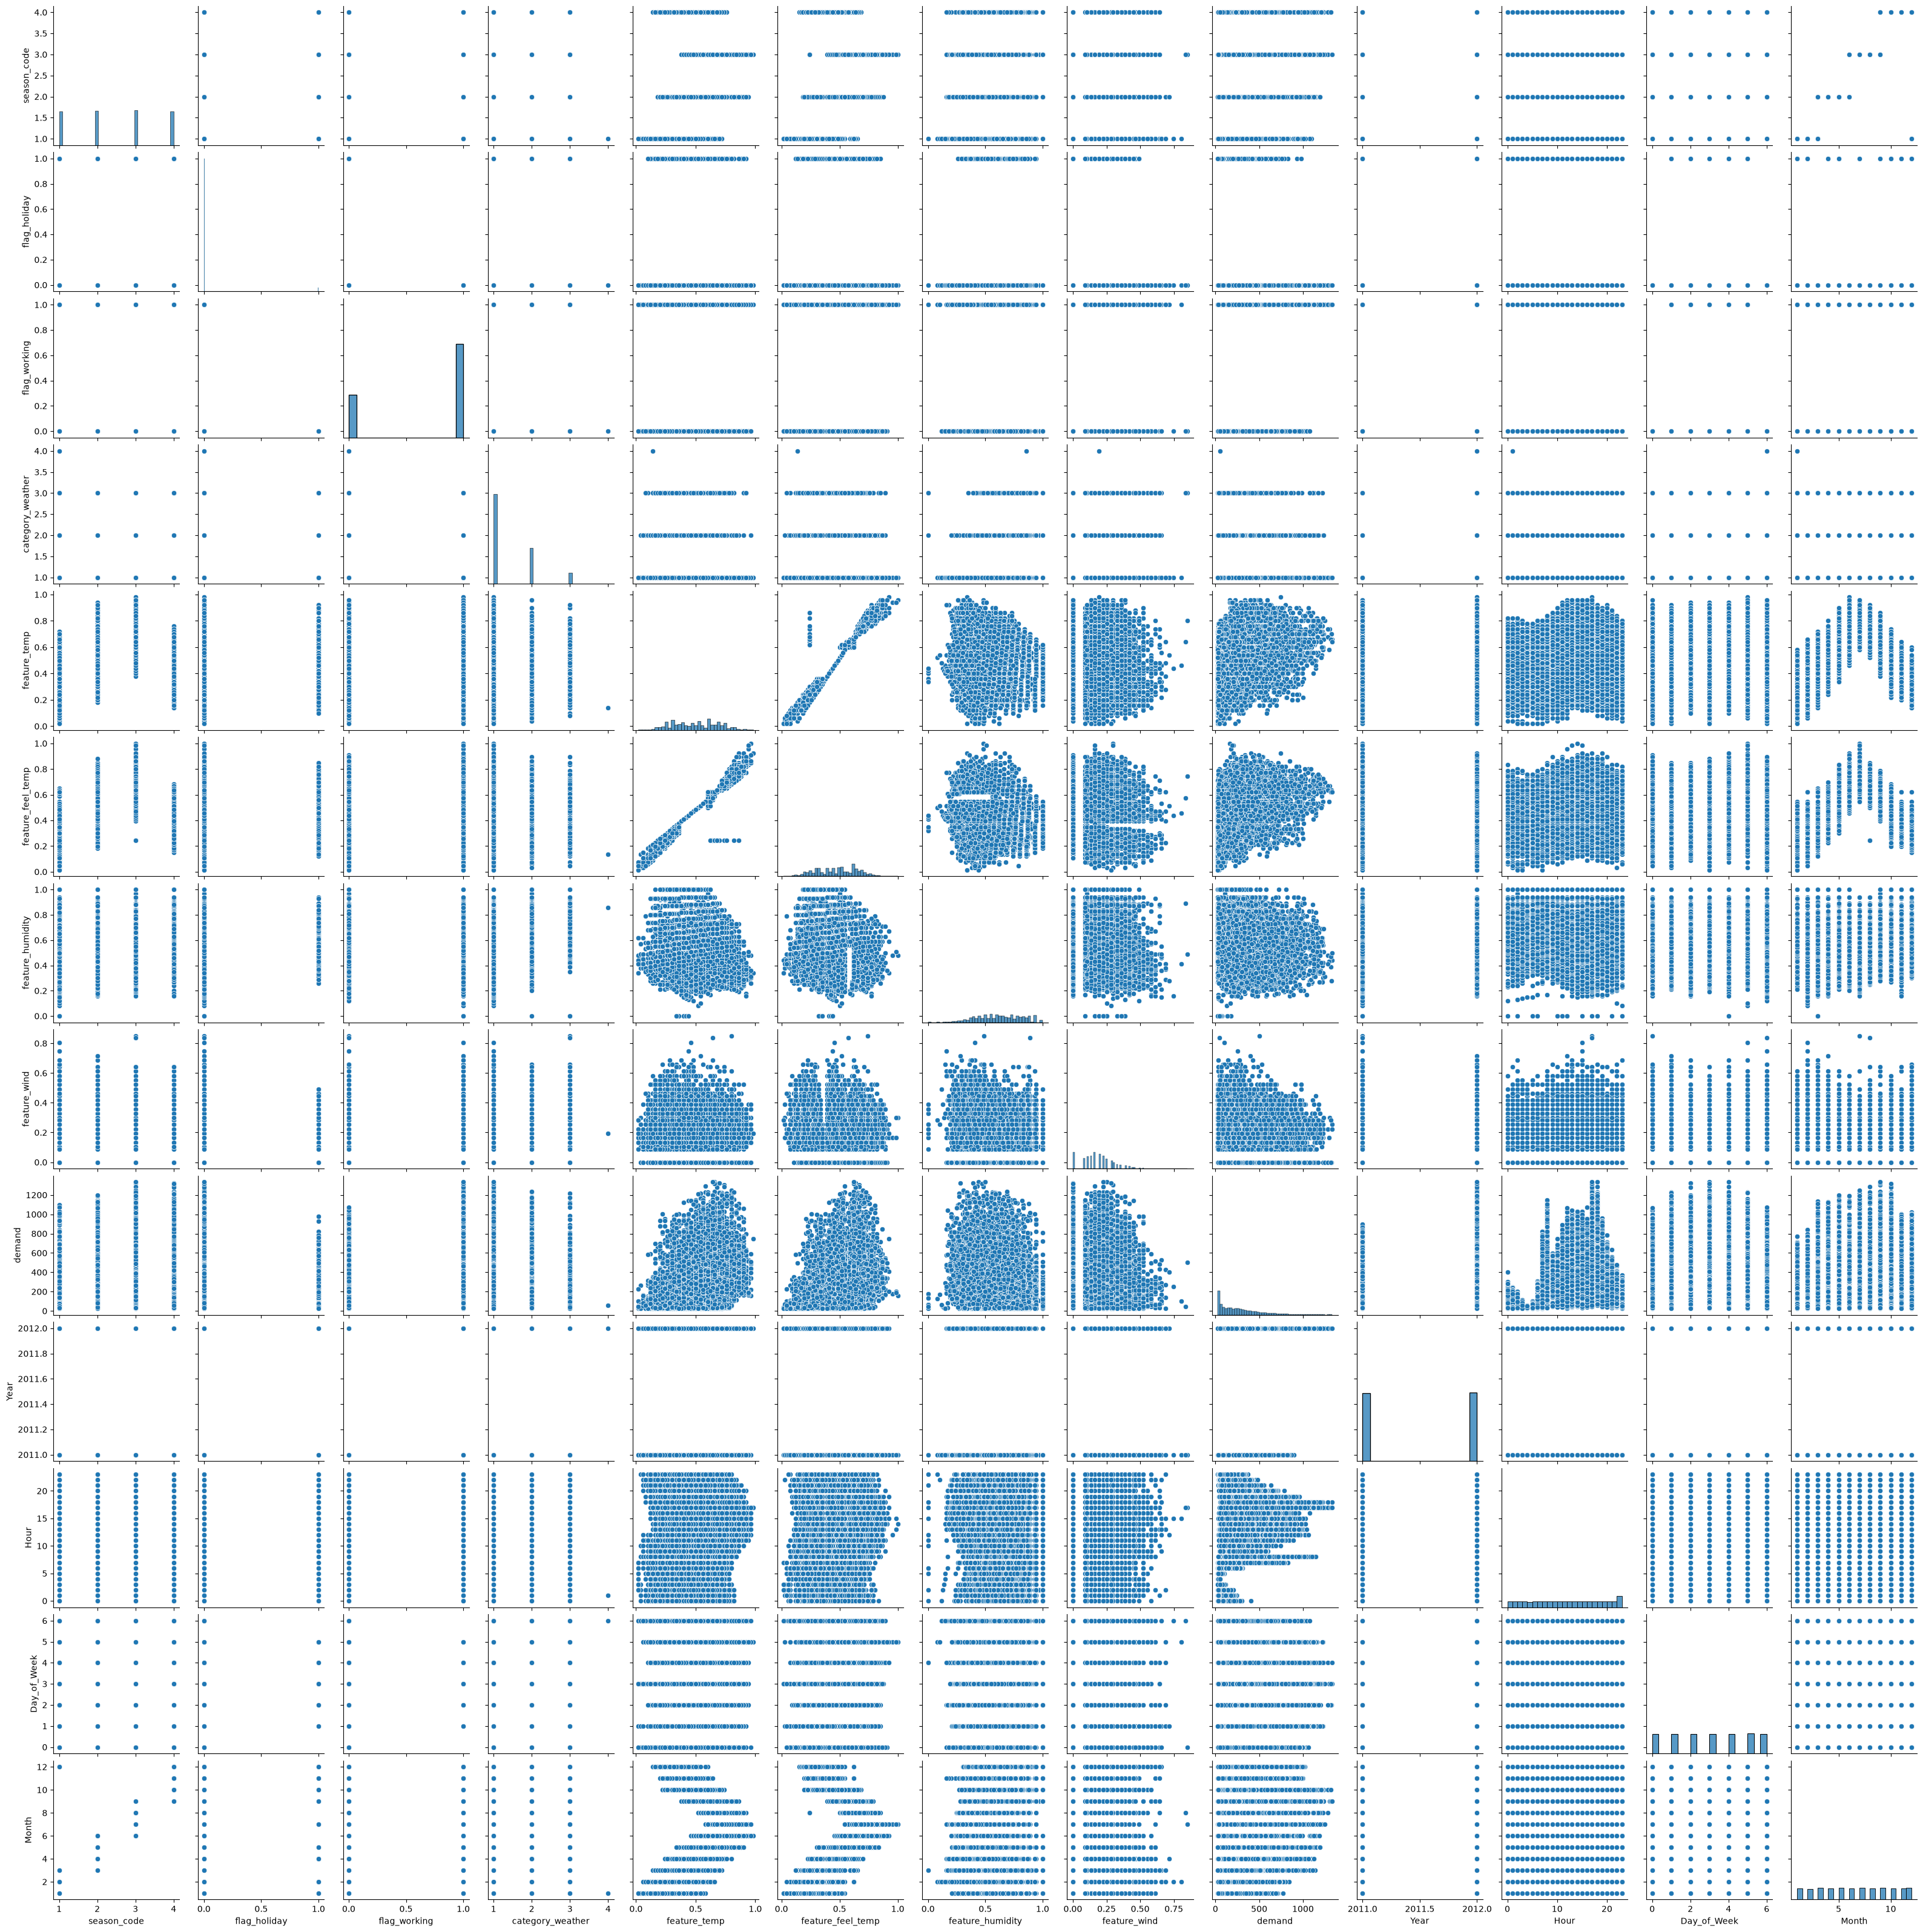

In [19]:
sns.pairplot(df_train.drop(columns = 'id'))

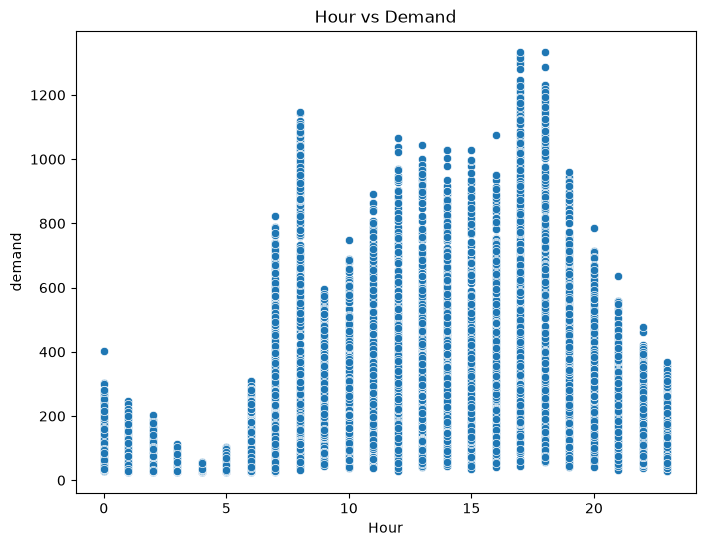

In [20]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Hour',y='demand',data=df_train)
plt.title("Hour vs Demand")
plt.show()

In [21]:
df_train['hour_sin'] = np.sin(2 * np.pi * df_train['Hour'] / 24.0)
df_train['hour_cos'] = np.cos(2 * np.pi * df_train['Hour'] / 24.0)
df_train['month_sin'] = np.sin(2 * np.pi * df_train['Month'] / 12.0)
df_train['month_cos'] = np.cos(2 * np.pi * df_train['Month'] / 12.0)

df_test['hour_sin'] = np.sin(2 * np.pi * df_test['Hour'] / 24.0)
df_test['hour_cos'] = np.cos(2 * np.pi * df_test['Hour'] / 24.0)
df_test['month_sin'] = np.sin(2 * np.pi * df_test['Month'] / 12.0)
df_test['month_cos'] = np.cos(2 * np.pi * df_test['Month'] / 12.0)

In [22]:
df_train["dow_sin"] = np.sin(2*np.pi*df_train.Day_of_Week/7)
df_train["dow_cos"] = np.cos(2*np.pi*df_train.Day_of_Week/7)

df_test["dow_sin"] = np.sin(2*np.pi*df_test.Day_of_Week/7)
df_test["dow_cos"] = np.cos(2*np.pi*df_test.Day_of_Week/7)

In [23]:
df_train['is_peak'] = df_train['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_train['is_weekend'] = (df_train['Day_of_Week'].isin([0,6])).astype(int)

df_test['is_peak'] = df_test['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_test['is_weekend'] = (df_test['Day_of_Week'].isin([0,6])).astype(int)


In [24]:
df_train["rush_bad_weather"] = (df_train["Hour"].isin([7,8,9,17,18,19]).astype(int)*df_train["category_weather"])
df_test["rush_bad_weather"] = (df_test["Hour"].isin([7,8,9,17,18,19]).astype(int)*df_test["category_weather"])

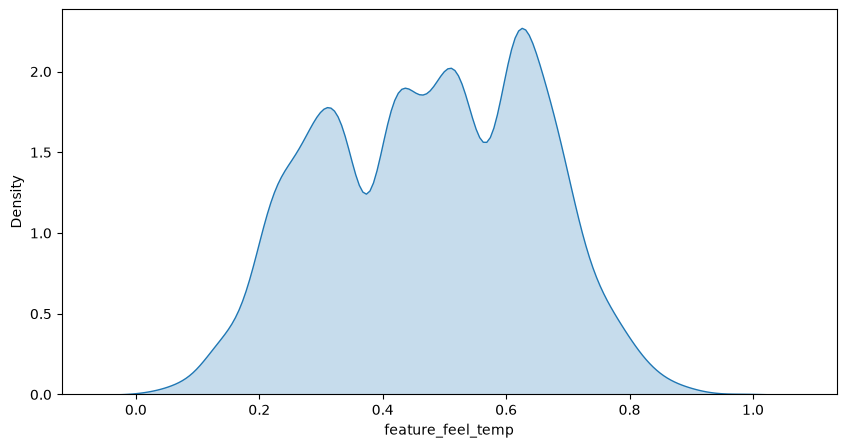

In [25]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_feel_temp'],fill=True)
plt.show()

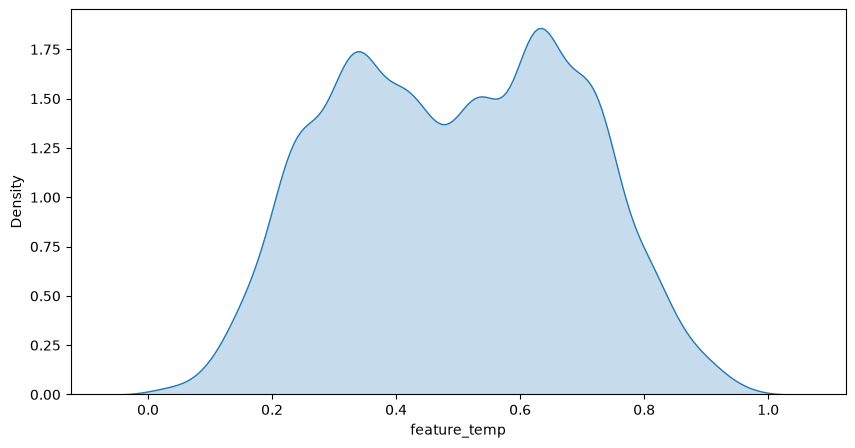

In [26]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_temp'],fill=True)
plt.show()

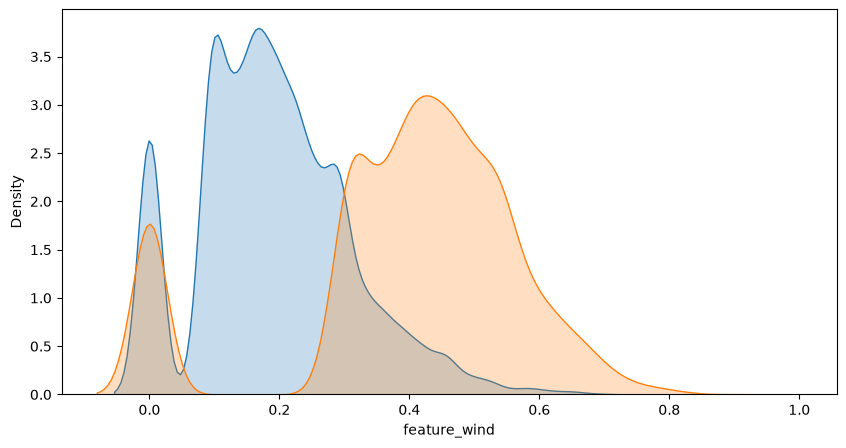

In [27]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_wind'],fill=True)
sns.kdeplot(np.sqrt(df_train['feature_wind']),fill=True)

plt.show()

In [28]:
df_train['feature_wind'] = np.sqrt(df_train['feature_wind'])
df_test['feature_wind'] = np.sqrt(df_test['feature_wind'])

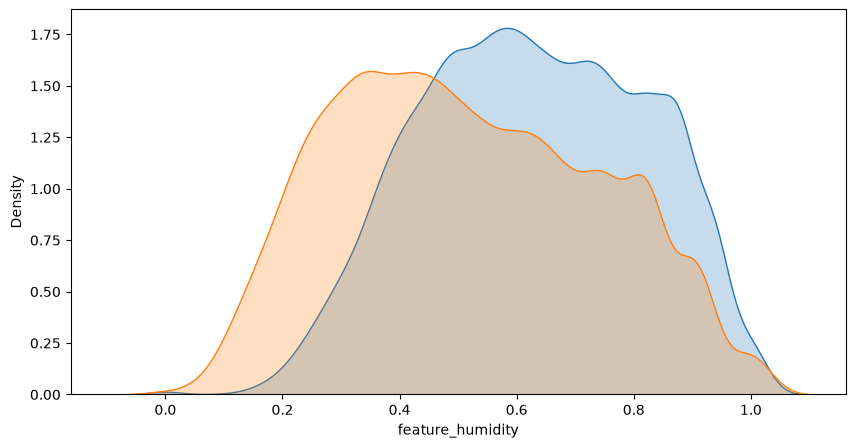

In [29]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_humidity'],fill=True)
sns.kdeplot(np.power(df_train['feature_humidity'], 1.5),fill=True)
plt.show()

In [30]:
df_train['feature_humidity'] = np.power(df_train['feature_humidity'], 1.5)
df_test['feature_humidity'] = np.power(df_test['feature_humidity'], 1.5)

In [31]:
# from sklearn.preprocessing import PowerTransformer

# pt_yj = PowerTransformer(method='yeo-johnson')

# df_train['feature_humidity'] = pt_yj.fit_transform(df_train[['feature_humidity']])
# df_test['feature_humidity'] = pt_yj.transform(df_test[['feature_humidity']])

In [32]:
# plt.figure(figsize=(10,5))
# sns.kdeplot(df_train['feature_humidity'],fill=True)
# sns.kdeplot(np.power(df_train['feature_humidity'], 1.5),fill=True)
# plt.show()

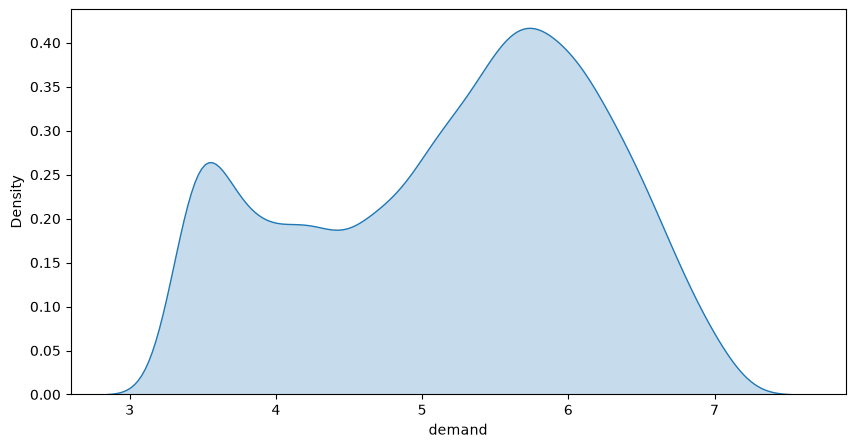

In [33]:
plt.figure(figsize=(10,5))
sns.kdeplot(np.log1p(df_train['demand']),fill=True)

plt.show()

In [34]:
ohe_cols = ['season_code', 'category_weather', 'Day_of_Week', 'Hour', 'Year', 'Month']

for col in ohe_cols:
    if col in df_train.columns:
        df_train[col] = df_train[col].astype(str)
        df_test[col] = df_test[col].astype(str)

df_train = pd.get_dummies(df_train, columns=ohe_cols, drop_first=True, dtype=int)
df_test = pd.get_dummies(df_test, columns=ohe_cols, drop_first=True, dtype=int)


In [35]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_temp',
       'feature_feel_temp', 'feature_humidity', 'feature_wind', 'demand',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos',
       'is_peak', 'is_weekend', 'rush_bad_weather', 'season_code_2',
       'season_code_3', 'season_code_4', 'category_weather_2',
       'category_weather_3', 'category_weather_4', 'Day_of_Week_1',
       'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4', 'Day_of_Week_5',
       'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13',
       'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19',
       'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_3',
       'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Year_2012',
       'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4',
       'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9'],
      dtype='str')

In [36]:
df_train.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,1,0,1,0.26,0.2576,0.585662,0.405216,34,0.500000,0.866025,...,1,0,0,0,0,0,0,0,0,0
1,2,0,1,0.58,0.5455,0.512000,0.000000,341,0.258819,-0.965926,...,0,0,0,0,0,0,0,0,0,0
2,3,0,0,0.22,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,...,0,0,0,0,0,0,0,0,0,0
3,4,0,1,0.36,0.3636,0.536187,0.323265,40,0.258819,0.965926,...,0,1,0,0,0,0,0,0,0,0
4,5,0,0,0.04,0.0606,0.262528,0.405216,96,0.500000,-0.866025,...,0,0,0,0,0,0,0,0,0,0


In [37]:
df_test.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,12166,0,1,0.62,0.5909,0.688877,0.405216,1.000000,6.123234e-17,1.224647e-16,...,0,0,0,0,0,0,1,0,0,0
1,12167,0,1,0.70,0.6667,0.702167,0.440454,0.000000,1.000000e+00,5.000000e-01,...,0,0,0,0,0,1,0,0,0,0
2,12168,0,1,0.32,0.3030,0.301869,0.503686,-0.500000,-8.660254e-01,-2.449294e-16,...,0,1,0,0,0,0,0,0,0,0
3,12169,1,0,0.16,0.1515,0.407891,0.440454,0.258819,-9.659258e-01,5.000000e-01,...,0,0,0,0,0,0,0,0,0,0
4,12170,0,1,0.52,0.5000,0.500047,0.299333,0.258819,9.659258e-01,1.000000e+00,...,0,0,0,1,0,0,0,0,0,0


In [38]:
numeric_df = df_train.drop(columns='id').select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
flag_holiday,1.000000,-0.252696,-0.032358,-0.035302,-0.010322,-0.004081,-0.036413,-0.001239,0.002688,-0.008113,...,0.055820,0.013629,0.003271,-0.052148,0.006840,0.006474,-0.051317,0.003864,-0.051623,0.009695
flag_working,-0.252696,1.000000,0.048867,0.047249,0.017249,-0.011838,0.024296,0.004307,-0.001660,0.002182,...,-0.010618,-0.012658,0.003833,0.027322,-0.015638,0.003434,0.023552,-0.016134,0.042937,-0.010591
feature_temp,-0.032358,0.048867,1.000000,0.988547,-0.064564,-0.008644,0.400890,-0.181591,-0.131321,-0.450421,...,-0.203404,-0.271841,-0.295453,-0.170727,-0.041338,0.155346,0.292721,0.412641,0.333158,0.188394
feature_feel_temp,-0.035302,0.047249,0.988547,1.000000,-0.049806,-0.046653,0.397118,-0.174685,-0.124425,-0.442252,...,-0.193605,-0.264378,-0.294119,-0.169479,-0.032294,0.159633,0.285042,0.408826,0.311798,0.182142
feature_humidity,-0.010322,0.017249,-0.064564,-0.049806,1.000000,-0.219311,-0.318492,0.345799,0.262666,-0.140186,...,-0.006230,0.060133,-0.098238,-0.048544,-0.048088,0.094585,-0.074406,-0.053858,0.006305,0.137208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Month_5,0.006474,0.003434,0.155346,0.159633,0.094585,0.006605,0.042711,0.008406,0.003658,0.218605,...,-0.091762,-0.092648,-0.088966,-0.092796,-0.090720,1.000000,-0.091316,-0.093480,-0.091861,-0.092992
Month_6,-0.051317,0.023552,0.292721,0.285042,-0.074406,0.006676,0.078620,-0.005477,-0.001789,0.003099,...,-0.090395,-0.091268,-0.087641,-0.091413,-0.089369,-0.091316,1.000000,-0.092088,-0.090492,-0.091606
Month_7,0.003864,-0.016134,0.412641,0.408826,-0.053858,-0.047432,0.074340,0.010310,-0.000520,-0.214106,...,-0.092537,-0.093431,-0.089718,-0.093579,-0.091487,-0.093480,-0.092088,1.000000,-0.092637,-0.093777
Month_8,-0.051623,0.042937,0.333158,0.311798,0.006305,-0.050026,0.085519,0.004129,-0.003977,-0.366698,...,-0.090934,-0.091812,-0.088163,-0.091958,-0.089901,-0.091861,-0.090492,-0.092637,1.000000,-0.092152


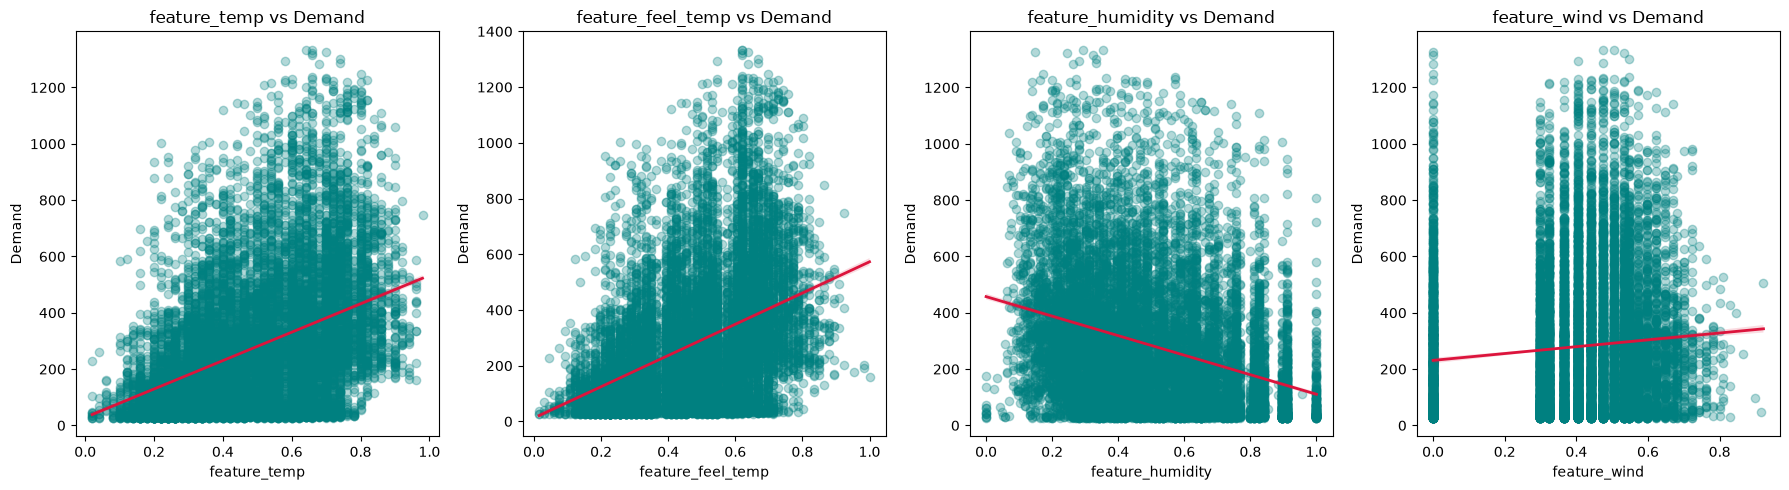

In [39]:
features = ["feature_temp", "feature_feel_temp", "feature_humidity", "feature_wind"]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y="demand",
        ax=ax[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    ax[i].set_title(f"{col} vs Demand")
    ax[i].set_ylabel("Demand")
    ax[i].set_xlabel(col)

plt.tight_layout()
plt.show()

In [40]:
df_train = df_train.drop(columns = 'feature_temp')
df_test = df_test.drop(columns = 'feature_temp')

In [41]:
hour_cols = [c for c in df_train.columns if c.startswith('Hour_') and '_Workday' not in c]

for col in hour_cols:
    df_train[f'{col}_Workday'] = df_train[col] * df_train['flag_working']
    df_test[f'{col}_Workday'] = df_test[col] * df_test['flag_working']

In [42]:
df_train['wind_workday'] = df_train['feature_wind'] * df_train['flag_working']
df_test['wind_workday'] = df_test['feature_wind'] * df_test['flag_working']

df_train['humidity_workday'] = df_train['feature_humidity'] * df_train['flag_working']
df_test['humidity_workday'] = df_test['feature_humidity'] * df_test['flag_working']

In [43]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'demand', 'hour_sin', 'hour_cos',
       'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'is_peak', 'is_weekend',
       'rush_bad_weather', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_1_Workday', 'Hour_10_Workday', 'Hour_11_Workday',
       'Hour_12_Workday', 'Hour

In [44]:
df_train.head()

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Hour_23_Workday,Hour_3_Workday,Hour_4_Workday,Hour_5_Workday,Hour_6_Workday,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,wind_workday,humidity_workday
0,1,0,1,0.2576,0.585662,0.405216,34,0.500000,0.866025,-5.000000e-01,...,0,0,0,0,0,0,0,0,0.405216,0.585662
1,2,0,1,0.5455,0.512000,0.000000,341,0.258819,-0.965926,-8.660254e-01,...,0,0,0,0,0,0,0,0,0.000000,0.512000
2,3,0,0,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,-8.660254e-01,...,0,0,0,0,0,0,0,0,0.000000,0.000000
3,4,0,1,0.3636,0.536187,0.323265,40,0.258819,0.965926,-2.449294e-16,...,0,0,0,0,0,0,0,0,0.323265,0.536187
4,5,0,0,0.0606,0.262528,0.405216,96,0.500000,-0.866025,5.000000e-01,...,0,0,0,0,0,0,0,0,0.000000,0.000000


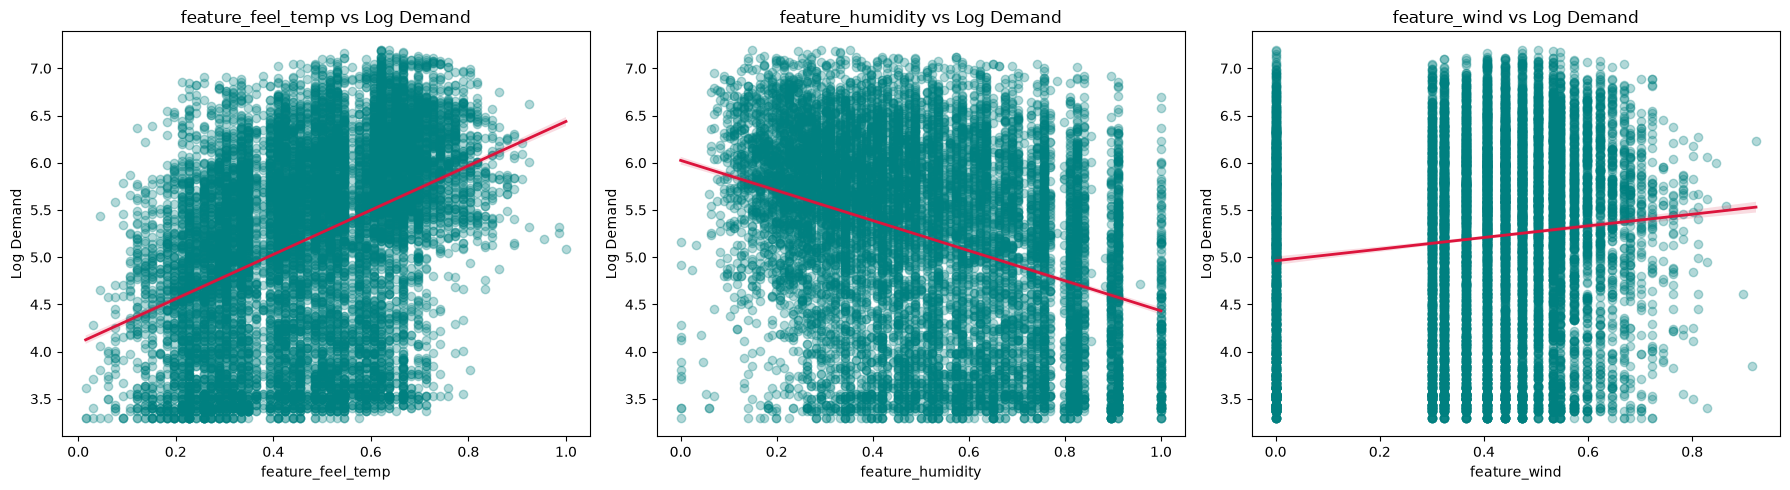

In [45]:
features = ["feature_feel_temp", "feature_humidity", "feature_wind"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y=np.log1p(df_train["demand"]),
        ax=ax[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    ax[i].set_title(f"{col} vs Log Demand")
    ax[i].set_ylabel("Log Demand")
    ax[i].set_xlabel(col)

plt.tight_layout()
plt.show()

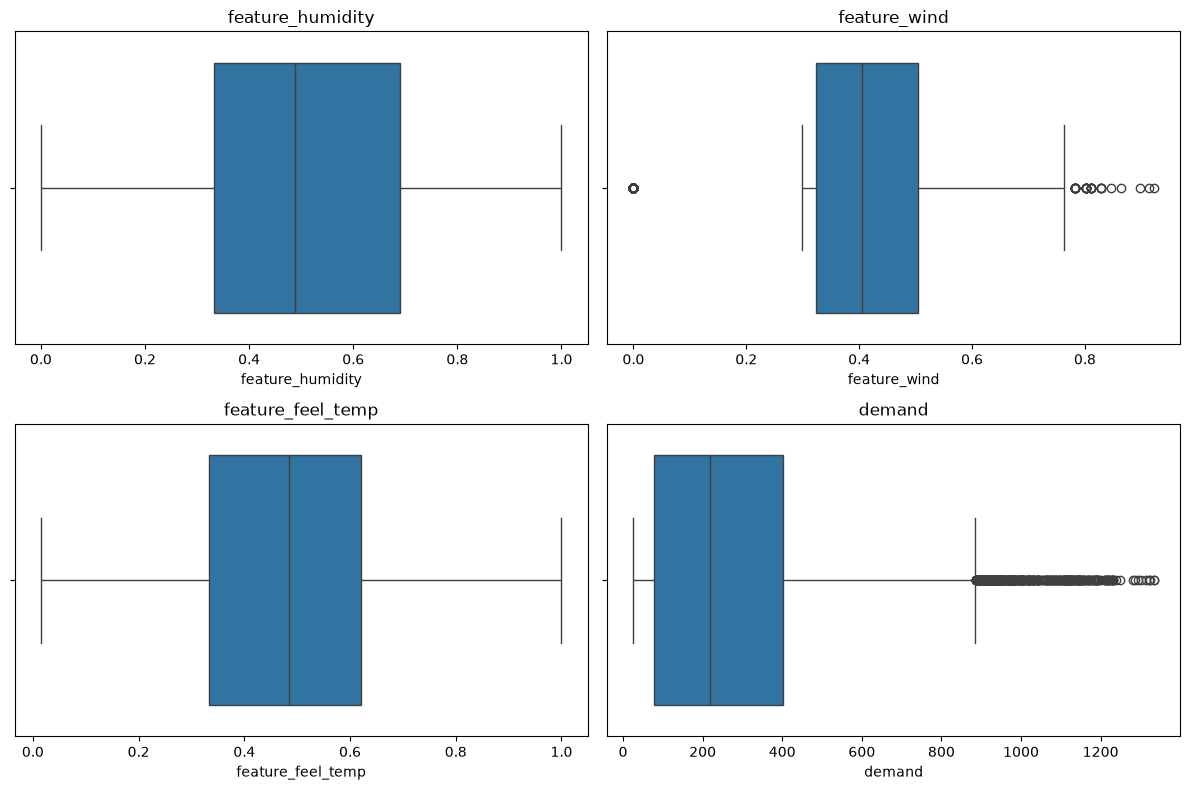

In [46]:
outlier_check_cols = ["feature_humidity", "feature_wind", "feature_feel_temp", "demand"]

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

for i, col in enumerate(outlier_check_cols):
    sns.boxplot(data=df_train, x=col, ax=ax[i])
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

In [47]:
lower_bound = 0.15
higher_bound = 0.75

df_train["feature_wind"] = df_train["feature_wind"].clip(
    lower = lower_bound,
    upper = higher_bound
)
df_test["feature_wind"] = df_test["feature_wind"].clip(
    lower = lower_bound,
    upper = higher_bound
)

<Axes: xlabel='feature_wind'>

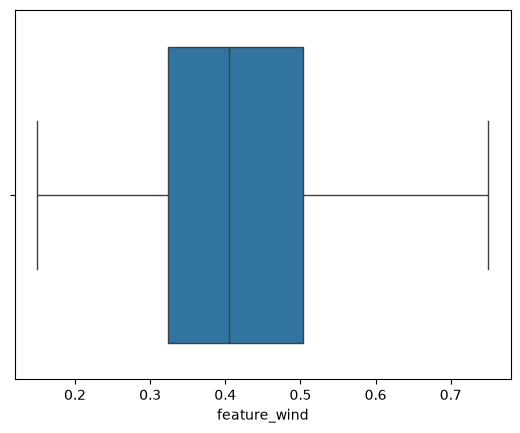

In [48]:
sns.boxplot(x='feature_wind', data=df_train)

In [49]:
new_order = [col for col in df_train.columns if col != 'demand'] + ['demand']
df_train = df_train[new_order]

In [50]:
df_train.sample(10)

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,month_cos,...,Hour_3_Workday,Hour_4_Workday,Hour_5_Workday,Hour_6_Workday,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,wind_workday,humidity_workday,demand
2937,2938,0,1,0.4697,0.332554,0.440454,0.707107,-0.707107,1.000000,6.123234e-17,...,0,0,0,0,0,0,1,0.440454,0.332554,455
9,10,0,1,0.3485,0.729000,0.473181,-0.965926,-0.258819,-0.500000,8.660254e-01,...,0,0,0,0,0,0,0,0.473181,0.729000,262
10815,10816,0,0,0.3485,0.419066,0.405216,0.965926,0.258819,0.866025,-5.000000e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,29
3798,3799,0,1,0.2727,0.896860,0.150000,0.000000,1.000000,0.500000,8.660254e-01,...,0,0,0,0,0,0,0,0.000000,0.896860,29
2624,2625,0,1,0.5000,1.000000,0.299333,-0.707107,0.707107,-1.000000,-1.836970e-16,...,0,0,0,0,0,0,0,0.299333,1.000000,293
5834,5835,0,1,0.6364,0.573157,0.622977,0.258819,-0.965926,0.500000,-8.660254e-01,...,0,0,0,0,0,0,0,0.622977,0.573157,266
9236,9237,0,0,0.2273,0.374977,0.440454,0.258819,0.965926,1.000000,6.123234e-17,...,0,0,0,0,0,0,0,0.000000,0.000000,52
2132,2133,0,1,0.3333,0.281970,0.546352,0.866025,0.500000,1.000000,6.123234e-17,...,0,1,0,0,0,0,0,0.546352,0.281970,26
5320,5321,0,1,0.3485,0.252982,0.473181,-0.866025,-0.500000,-0.500000,8.660254e-01,...,0,0,0,0,0,0,0,0.473181,0.252982,521
9627,9628,0,0,0.4091,0.536187,0.150000,-0.707107,0.707107,-0.500000,8.660254e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,320


In [51]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'hour_sin', 'hour_cos', 'month_sin',
       'month_cos', 'dow_sin', 'dow_cos', 'is_peak', 'is_weekend',
       'rush_bad_weather', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_1_Workday', 'Hour_10_Workday', 'Hour_11_Workday',
       'Hour_12_Workday', 'Hour_13_Workda

In [52]:
X = df_train.drop(columns=['id', 'demand'])
y = df_train['demand']

feature_cols = ['feature_feel_temp', 'feature_humidity', 'feature_wind', 'hour_sin', 'hour_cos', 'flag_working', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
y_train_log = np.log1p(y_train)

<Axes: xlabel='demand'>

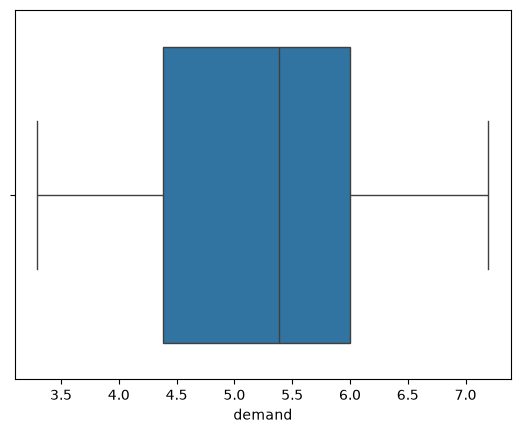

In [54]:
sns.boxplot(x=y_train_log, data=df_train)

In [55]:
poly = PolynomialFeatures(degree = 4, include_bias = False)

X_train_poly = poly.fit_transform(X_train[feature_cols])
X_test_poly = poly.transform(X_test[feature_cols])

poly_cols = poly.get_feature_names_out(feature_cols)

X_train_poly = pd.DataFrame(X_train_poly, columns=poly_cols, index=X_train.index)
X_test_poly = pd.DataFrame(X_test_poly, columns=poly_cols, index=X_test.index)

In [56]:
X_train_rest = X_train.drop(columns=feature_cols)
X_test_rest = X_test.drop(columns=feature_cols)

In [57]:
X_train_final = pd.concat([X_train_rest, X_train_poly], axis=1)
X_test_final = pd.concat([X_test_rest, X_test_poly], axis=1)

In [58]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [59]:
alphas = np.logspace(-4, 4, 60)

regcv = RidgeCV(alphas = alphas, cv = 5)
regcv.fit(X_train_scaled, y_train_log)

print("Best alpha:", regcv.alpha_)


Best alpha: 14.208308325339209


In [60]:
y_pred_log = regcv.predict(X_test_scaled)
y_pred = np.expm1(y_pred_log)

In [61]:
r2_score(y_test, y_pred)

0.9287062804463313

In [62]:
root_mean_squared_log_error(y_test, y_pred)

0.22998737524598986

In [63]:
y_full_raw = df_train['demand']
y_full_log = np.log1p(y_full_raw)
X_full = X.copy()

poly = PolynomialFeatures(degree=4,include_bias=False)

X_full_poly = poly.fit_transform(X_full[feature_cols])

poly_cols = poly.get_feature_names_out(feature_cols)

X_full_poly = pd.DataFrame(X_full_poly,columns=poly_cols,index=X_full.index)

X_full_other = X_full.drop(columns=feature_cols)

X_full_processed = pd.concat([X_full_other, X_full_poly],axis=1)

sscaler = StandardScaler()

X_full_processed[poly_cols] = sscaler.fit_transform(X_full_processed[poly_cols])

modelcv = RidgeCV(alphas=alphas,cv=5)
modelcv.fit(X_full_processed, y_full_log)
print("Best alpha:", modelcv.alpha_)

Best alpha: 5.568813990945267


In [64]:
X_test = df_test.drop(columns=["id", "demand"], errors="ignore")
X_test = X_test.reindex(columns=X_full.columns, fill_value=0)

X_poly = pd.DataFrame(poly.transform(X_test[feature_cols]),columns=poly_cols,index=X_test.index)

X_test = pd.concat([X_test.drop(columns=feature_cols), X_poly],axis=1)

X_test[poly_cols] = sscaler.transform(X_test[poly_cols])

pred = np.clip(np.expm1(modelcv.predict(X_test)),0,None)

submission = pd.DataFrame({
    "id": df_test["id"],
    "demand": pred
})

submission.to_csv("submission4.csv", index=False)

In [65]:
# coef = pd.Series(
#     regcv.coef_,
#     index=X_full_processed.columns
# )

# coef = coef.sort_values(key=np.abs, ascending=False)

# print(coef.head(30))

In [66]:
# coef.tail(20)

In [67]:
X_test_final.head()

,flag_holiday,is_peak,is_weekend,rush_bad_weather,season_code_2,season_code_3,season_code_4,category_weather_2,category_weather_3,category_weather_4,...,dow_cos^2 month_cos^2,dow_cos month_sin^3,dow_cos month_sin^2 month_cos,dow_cos month_sin month_cos^2,dow_cos month_cos^3,month_sin^4,month_sin^3 month_cos,month_sin^2 month_cos^2,month_sin month_cos^3,month_cos^4
8522,0,0,0,0,0,1,0,1,0,0,...,0.291555,-7.793623e-02,-1.349895e-01,-2.338087e-01,-0.404969,6.250000e-02,1.082532e-01,1.875000e-01,3.247595e-01,0.5625
4046,1,1,0,2,0,0,1,1,0,0,...,0.097185,-4.049685e-01,2.338087e-01,-1.349895e-01,0.077936,5.625000e-01,-3.247595e-01,1.875000e-01,-1.082532e-01,0.0625
8297,0,0,1,0,0,1,0,0,0,0,...,0.250000,-6.495191e-01,-3.750000e-01,-2.165064e-01,-0.125000,5.625000e-01,3.247595e-01,1.875000e-01,1.082532e-01,0.0625
7118,0,0,0,0,0,0,1,0,0,0,...,0.811745,1.323830e-47,-5.404947e-32,2.206737e-16,-0.900969,3.598847e-63,-1.469341e-47,5.999039e-32,-2.449294e-16,1.0000
10258,0,0,0,0,0,1,0,0,0,0,...,0.811745,-1.654788e-48,1.351237e-32,-1.103369e-16,0.900969,2.249279e-64,-1.836676e-48,1.499760e-32,-1.224647e-16,1.0000


In [68]:
X_test_final.columns

Index(['flag_holiday', 'is_peak', 'is_weekend', 'rush_bad_weather',
       'season_code_2', 'season_code_3', 'season_code_4', 'category_weather_2',
       'category_weather_3', 'category_weather_4',
       ...
       'dow_cos^2 month_cos^2', 'dow_cos month_sin^3',
       'dow_cos month_sin^2 month_cos', 'dow_cos month_sin month_cos^2',
       'dow_cos month_cos^3', 'month_sin^4', 'month_sin^3 month_cos',
       'month_sin^2 month_cos^2', 'month_sin month_cos^3', 'month_cos^4'],
      dtype='str', length=1076)